# 06 — Aplicação Estratégica (Fase 3)

Responde às perguntas de negócio do enunciado com o modelo treinado:

1. Quais municípios apresentam maior risco educacional?
2. Como prever municípios que podem não atingir metas futuras?
3. Quais regiões possuem padrões semelhantes?

(Quais fatores mais impactam / quais variáveis mais influenciam: notebook 05.)

Fonte: `reports/*.csv` e `reports/aplicacao_estrategica.json`, gerados por
`rodar_aplicacao_estrategica()` em `src/modeling/treinar.py`.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT))
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
plt.rcParams["figure.dpi"] = 100

E = json.loads((ROOT / "reports" / "aplicacao_estrategica.json").read_text(encoding="utf-8"))

## 1. Municípios de maior risco educacional

Predições **out-of-fold**: cada município é avaliado por um modelo que nunca
viu nenhum aluno dele. Só municípios com pelo menos 30 alunos avaliados.

,nome_municipio,sigla_uf,n_alunos,risco_previsto,taxa_real
0,Poço Branco,RN,65,86.17,25.35
1,Espírito Santo,RN,72,84.03,47.09
2,Iramaia,BA,33,79.03,36.36
3,Ceará-Mirim,RN,654,78.79,34.66
4,Entre Rios,BA,255,78.57,32.55
5,Cuité de Mamanguape,PB,65,77.91,22.19
6,Gurupá,PA,473,77.87,38.23
7,Jardim de Angicos,RN,38,77.67,31.59
8,Itanagra,BA,53,77.62,24.53
9,Cabaceiras do Paraguaçu,BA,119,77.25,32.77


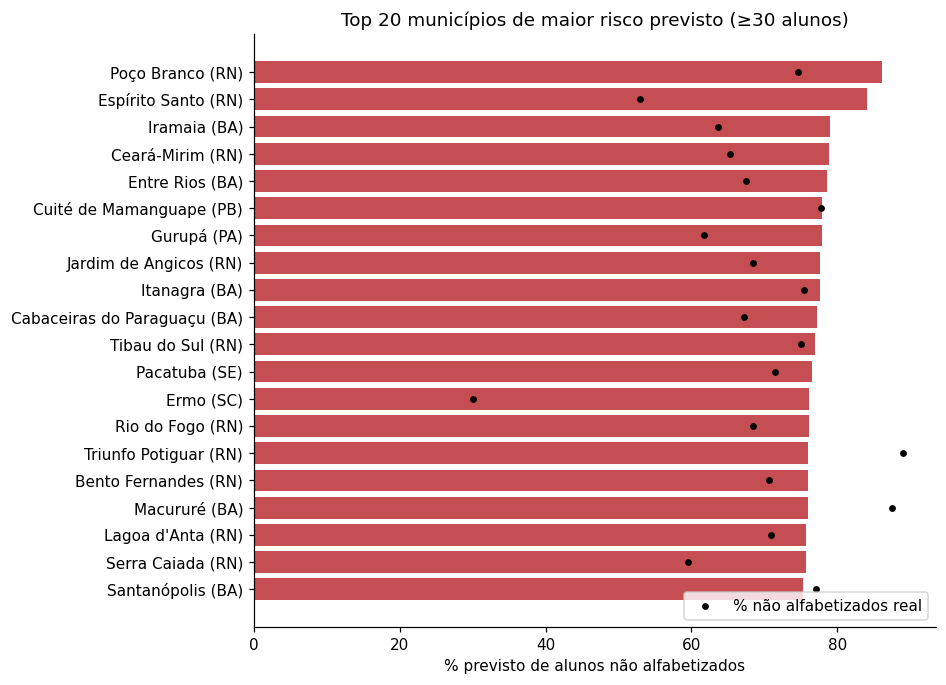

UFs mais frequentes no top 50: {'BA': 19, 'RN': 14, 'TO': 5, 'SE': 4, 'PB': 3}


In [2]:
ranking = pd.read_csv(ROOT / "reports" / "ranking_risco_municipios.csv", dtype={"id_municipio": str})
display(ranking.head(15)[["nome_municipio", "sigla_uf", "n_alunos", "risco_previsto", "taxa_real"]])
display(Image(filename=str(ROOT / "images" / "13_ranking_risco_municipios.png")))
print("UFs mais frequentes no top 50:", ranking["sigla_uf"].value_counts().head(5).to_dict())

## 2. Metas futuras

### 2a. Backtest: o modelo teria antecipado quem não bateu a meta de 2024?

Rede municipal (escopo das metas municipais), taxa agregada com o peso
amostral do aluno.

municipios_avaliados         4677
mae_taxa_pp                  9.71
correlacao_prevista_real     0.7422
real_abaixo_meta             2169
previsto_abaixo_meta         2169
precisao_alerta              0.6113
recall_alerta                0.6113
acuracia_alerta              0.6395


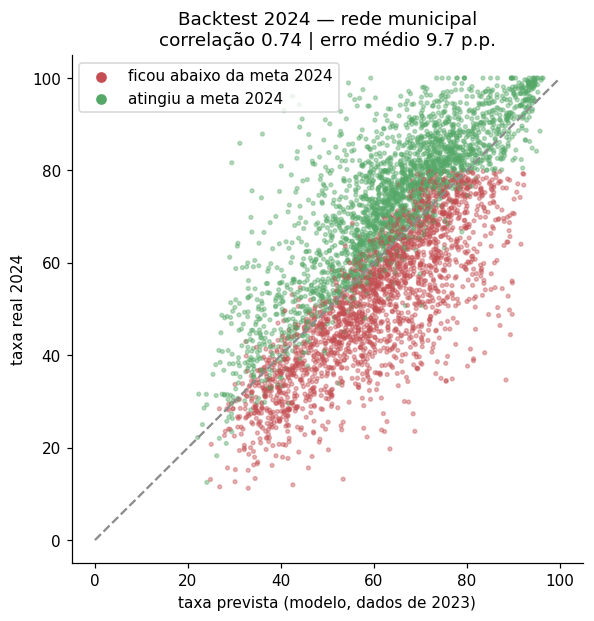

In [3]:
bt = E["backtest_meta"]
for k, v in bt.items():
    print(f"{k:28s} {v}")
display(Image(filename=str(ROOT / "images" / "12_backtest_meta_2024.png")))

**H4**: compare a correlação município a município (acima) com o ROC-AUC
individual do notebook 05. Errar alunos individualmente e acertar a taxa
do município são compatíveis — os erros individuais se compensam na média.
É no nível agregado que o modelo vira ferramenta de gestão.

### 2b. Projeção: quem tende a ficar abaixo da meta de 2025

,nome_regiao,municipios,em_risco,gap_medio_pp,pct_em_risco
0,Sul,853,673,-11.83,78.9
1,Norte,403,264,-4.27,65.5
2,Nordeste,1640,839,-1.21,51.2
3,Sudeste,1438,483,5.16,33.6
4,Centro-Oeste,426,123,5.19,28.9


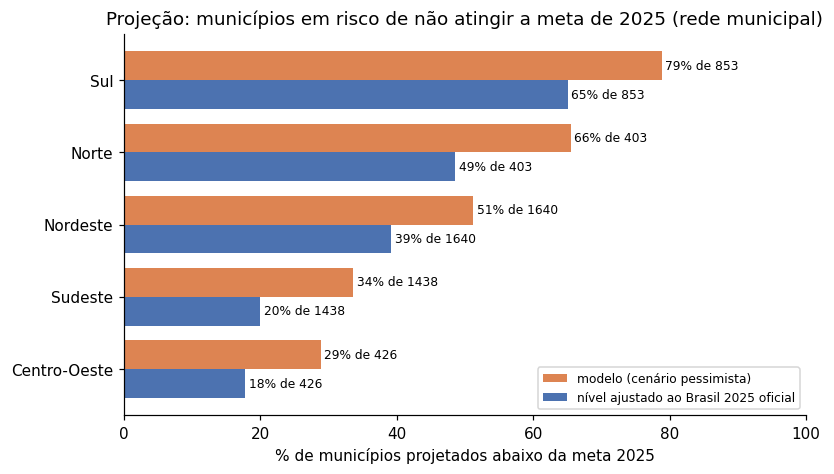

Maiores gaps projetados (taxa projetada − meta, p.p.):


,nome_municipio,sigla_uf,taxa_prevista,meta_ano,gap_projetado_pp
0,Anapurus,MA,16.83,80.00,-63.17
1,Sentinela do Sul,RS,13.47,75.70,-62.23
2,Marcação,PB,11.82,72.42,-60.60
3,Monte do Carmo,TO,12.84,73.10,-60.26
4,Pantano Grande,RS,16.20,74.82,-58.62
5,Pirapemas,MA,22.27,80.00,-57.73
6,Marajá do Sena,MA,22.44,80.00,-57.56
7,Barra do Turvo,SP,23.30,80.00,-56.70
8,Olinda Nova do Maranhão,MA,25.04,80.00,-54.96
9,Vale Real,RS,24.09,77.40,-53.31


In [4]:
proj = pd.read_csv(ROOT / "reports" / "projecao_meta_2025.csv", dtype={"id_municipio": str})
por_regiao = pd.read_csv(ROOT / "reports" / "projecao_meta_2025_por_regiao.csv")
display(por_regiao)
display(Image(filename=str(ROOT / "images" / "16_projecao_meta.png")))
print("Maiores gaps projetados (taxa projetada − meta, p.p.):")
display(proj.head(10)[["nome_municipio", "sigla_uf", "taxa_prevista", "meta_ano", "gap_projetado_pp"]])

In [5]:
# Checagem de plausibilidade: a projeção não pode se afastar muito do último resultado observado
bt_mun = pd.read_csv(ROOT / "reports" / "backtest_meta_2024.csv", dtype={"id_municipio": str})
compara = proj.merge(bt_mun[["id_municipio", "taxa_real"]], on="id_municipio", how="inner")
por_uf = compara.groupby("sigla_uf")[["taxa_real", "taxa_prevista"]].mean().round(1)
por_uf["diferenca"] = (por_uf["taxa_prevista"] - por_uf["taxa_real"]).round(1)
display(por_uf.sort_values("diferenca"))

,taxa_real,taxa_prevista,diferenca
sigla_uf,,,
PR,74.2,69.4,-4.8
RS,51.6,47.4,-4.2
SC,68.7,65.4,-3.3
RO,67.2,64.0,-3.2
PA,49.3,46.8,-2.5
RJ,58.3,56.1,-2.2
MA,63.3,61.6,-1.7
CE,90.3,89.4,-0.9
ES,78.2,77.4,-0.8


Projeção de 2025 vs. resultado real de 2024 por UF. Uma versão anterior
do modelo (com UF como feature) projetava 27,7% para o RS contra 51,6%
reais em 2024 — o choque das enchentes contado duas vezes. Esta checagem é
o que pegou o problema (ver D8 em `docs/decisoes_analiticas.md`).

### 2c. Validação fora do tempo: o Brasil de 2025 já foi divulgado

Os microdados param em 2024, mas o indicador **nacional** de 2025 já saiu.
É a única medida real do ano projetado — e o teste mais honesto da
projeção.

oficial_2024                     59.2
microdados_ponderado_2024        59.2
prevista_oof_2024                59.33
projetada_2025                   61.1
oficial_2025                     66.0
erro_projecao_2025_pp            -4.9
deslocamento_logit_ajuste        0.2356


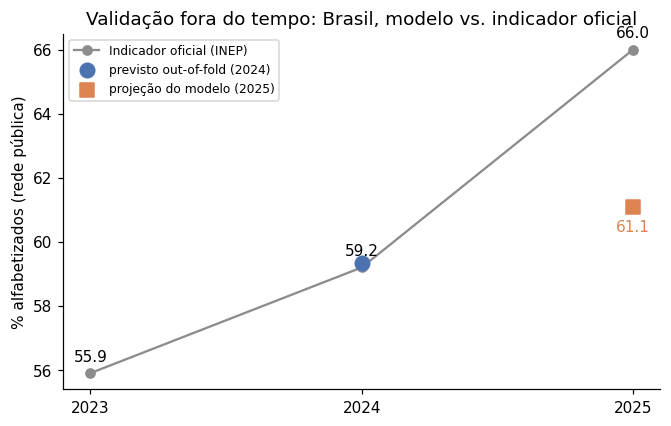

In [6]:
vt = E["validacao_temporal_nacional"]
for k, v in vt.items():
    print(f"{k:32s} {v}")
display(Image(filename=str(ROOT / "images" / "17_validacao_temporal_nacional.png")))

Três leituras:

1. **2024, microdados ponderados = oficial**: recalcular a taxa nacional a
   partir dos alunos, com o peso amostral, reproduz o número do INEP — a
   agregação usada em todo o notebook está correta.
2. **2024, previsto out-of-fold ≈ oficial**: somadas, as probabilidades do
   modelo batem a taxa real — a calibração vista no notebook 05 se sustenta
   no agregado.
3. **2025, projetado < oficial**: o modelo acerta a direção (sobe), mas
   subestima a magnitude. Aprendeu a relação de um único par de anos
   (2023→2024) e não antecipa uma aceleração nacional.

Por isso a projeção é apresentada em dois cenários (D20): o modelo puro
(pessimista) e o modelo com o **nível** ajustado ao Brasil 2025 oficial —
todas as probabilidades deslocadas igualmente em logit, o que preserva o
ranking de prioridade e corrige só o patamar.

In [7]:
aj = E["projecao_nivel_ajustado"]
p = E["projecao"]
print(f"Municípios abaixo da meta {p['ano']}: modelo puro {p['municipios_abaixo_meta']:,} de {p['municipios_avaliados']:,} "
      f"| nível ajustado a {aj['taxa_nacional_alvo']}%: {aj['municipios_abaixo_meta']:,}")
display(pd.read_csv(ROOT / "reports" / "projecao_meta_2025_nivel_ajustado_por_regiao.csv"))

Municípios abaixo da meta 2025: modelo puro 2,382 de 4,760 | nível ajustado a 66.0%: 1,757


,nome_regiao,municipios,em_risco,gap_medio_pp,pct_em_risco
0,Sul,853,555,-6.95,65.1
1,Norte,403,196,1.05,48.6
2,Nordeste,1640,643,3.39,39.2
3,Sudeste,1438,287,9.31,20.0
4,Centro-Oeste,426,76,9.19,17.8


## 3. Regiões com padrões semelhantes

Clusters (KMeans, k escolhido pelo silhouette) sobre o perfil observado do
município: taxa de alfabetização, proficiência média, desigualdade interna,
participação, IDHM Educação e Renda.

silhouette por k: {'3': 0.2658, '4': 0.2325, '5': 0.2215, '6': 0.2126, '7': 0.2054} -> k = 3


,cluster,taxa_alfabetizacao_ant,prof_media_ant,prof_desvio_ant,participacao_ant,idhm_educacao,idhm_renda,n_municipios
0,C1,83.309,775.934,34.368,94.599,0.550,0.628,1618
1,C2,62.467,751.670,42.762,88.460,0.638,0.714,2013
2,C3,45.493,734.667,42.330,90.680,0.475,0.571,1717


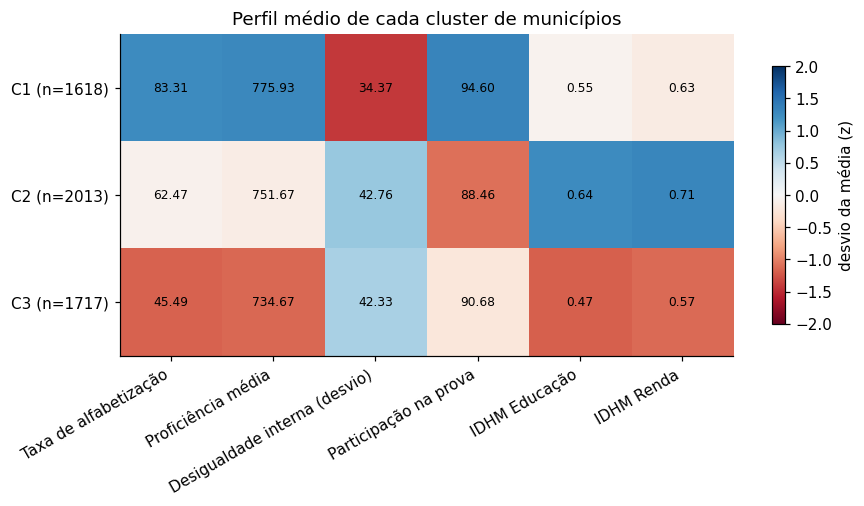

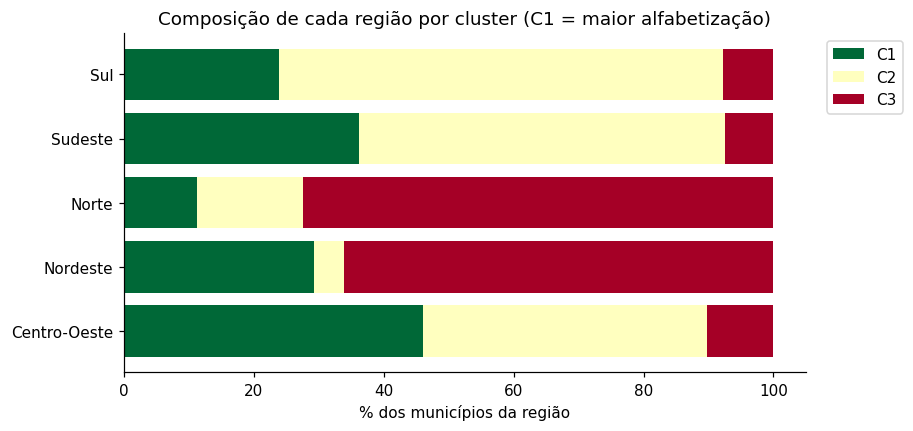

In [8]:
c = E["clusters"]
print("silhouette por k:", c["silhouette_por_k"], "-> k =", c["k_escolhido"])
display(pd.DataFrame(c["perfil"]))
display(Image(filename=str(ROOT / "images" / "14_clusters_perfil.png")))
display(Image(filename=str(ROOT / "images" / "15_clusters_por_regiao.png")))

In [9]:
clusters = pd.read_csv(ROOT / "reports" / "clusters_municipios.csv", dtype={"id_municipio": str})
melhor = clusters.groupby("cluster")["taxa_alfabetizacao_ant"].mean().idxmax()
c1 = clusters[clusters["cluster"] == melhor]
print(f"Cluster de maior alfabetização: {melhor} ({len(c1)} municípios)")
print("UFs mais representadas:", c1["sigla_uf"].value_counts().head(6).to_dict())
pct_uf = clusters.groupby("sigla_uf")["cluster"].apply(lambda s: (s == melhor).mean() * 100).sort_values(ascending=False)
print("\n% dos municípios de cada UF nesse cluster (top 5):", pct_uf.head().round(1).to_dict())

medias = clusters.groupby("cluster")[["taxa_alfabetizacao_ant", "idhm_educacao", "idhm_renda"]].mean().round(3)
print("\nMédias por cluster:")
display(medias)
mais_rico = medias["idhm_educacao"].idxmax()
ce = c1[c1["sigla_uf"] == "CE"]
print(f"Ceará no cluster {melhor}: taxa média {ce['taxa_alfabetizacao_ant'].mean():.1f}% | "
      f"IDHM Educação médio {ce['idhm_educacao'].mean():.3f}")
print(f"Cluster de IDHM Educação mais alto ({mais_rico}): taxa média "
      f"{medias.loc[mais_rico, 'taxa_alfabetizacao_ant']:.1f}% | IDHM Educação {medias.loc[mais_rico, 'idhm_educacao']:.3f}")

Cluster de maior alfabetização: C1 (1618 municípios)
UFs mais representadas: {'MG': 442, 'PR': 182, 'CE': 172, 'GO': 168, 'PI': 99, 'SP': 87}

% dos municípios de cada UF nesse cluster (top 5): {'CE': 93.5, 'GO': 68.6, 'ES': 64.1, 'MG': 54.0, 'PR': 45.7}

Médias por cluster:


,taxa_alfabetizacao_ant,idhm_educacao,idhm_renda
cluster,,,
C1,83.309,0.550,0.628
C2,62.467,0.638,0.714
C3,45.493,0.475,0.571


Ceará no cluster C1: taxa média 91.9% | IDHM Educação médio 0.550
Cluster de IDHM Educação mais alto (C2): taxa média 62.5% | IDHM Educação 0.638


**H5**: o cluster de maior alfabetização **não** é o de maior IDHM — tem
IDHM Educação e Renda menores que o cluster intermediário e, mesmo assim,
taxa de alfabetização bem maior (ver médias acima). O caso mais nítido é o
Ceará: quase todos os seus municípios estão no cluster de topo, com taxa
média acima de 90% e IDHM Educação bem abaixo do cluster mais rico. O
estado tem programa próprio de alfabetização há quase duas décadas (PAIC), que serviu de referência para o Compromisso Nacional Criança
Alfabetizada. Os dados não provam causalidade, mas mostram que contexto
socioeconômico desfavorável não é destino — e indicam onde buscar práticas
replicáveis.